In [3]:
from src.data.inventory import build_inventory

inventory = build_inventory("data/raw")
inventory["family"].value_counts()

family
new_2020_2026     79
old_2014_2016     16
old_2017_2019     10
stations           8
old_long_names     2
old_2013           1
Name: count, dtype: int64

In [5]:
import pandas as pd

# 1. Missing months
all_months = pd.period_range("2013-06", "2026-09", freq="M")
missing = all_months.difference(monthly["month"].unique())
print("Missing months:", list(missing))

# 2. Months found in more than one file
files_per_month = monthly.groupby("month")["csv"].nunique()
print("Months in several files:", list(files_per_month[files_per_month > 1].index))

Missing months: []
Months in several files: [Period('2024-05', 'M'), Period('2024-06', 'M'), Period('2024-07', 'M'), Period('2024-08', 'M'), Period('2024-09', 'M'), Period('2024-10', 'M'), Period('2024-11', 'M'), Period('2024-12', 'M'), Period('2025-01', 'M'), Period('2025-02', 'M'), Period('2025-03', 'M'), Period('2025-04', 'M'), Period('2025-05', 'M'), Period('2025-06', 'M'), Period('2025-07', 'M'), Period('2025-08', 'M'), Period('2025-09', 'M'), Period('2025-10', 'M'), Period('2025-11', 'M'), Period('2025-12', 'M'), Period('2026-01', 'M'), Period('2026-02', 'M'), Period('2026-04', 'M'), Period('2026-05', 'M'), Period('2026-06', 'M'), Period('2026-07', 'M'), Period('2026-08', 'M')]


In [6]:
share = monthly.groupby(["month", "csv"])["n_trips"].sum()
share = share / share.groupby("month").transform("sum")
overlaps = share[(share > 0.01) & (share < 0.99)]
print("Months really covered by two files:\n", overlaps)

Months really covered by two files:
 Series([], Name: n_trips, dtype: float64)


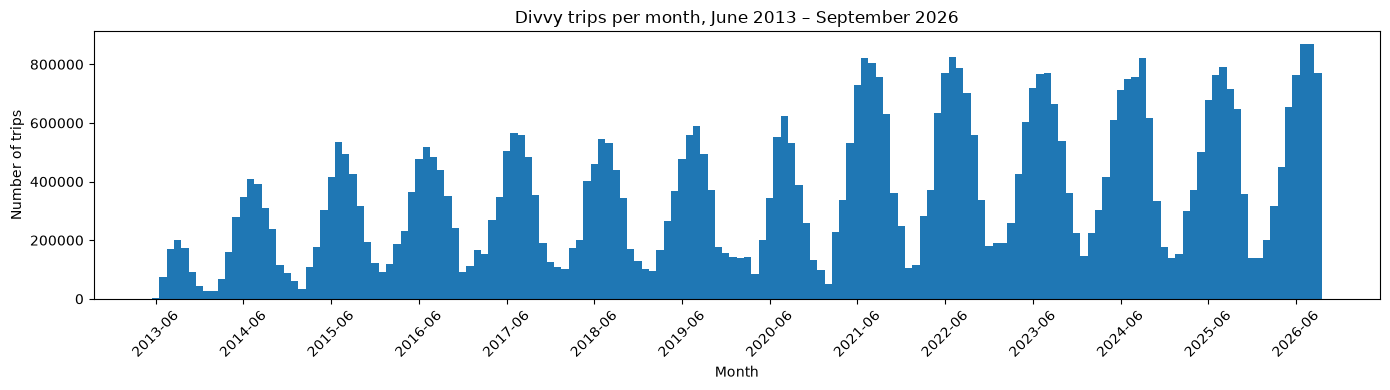

In [9]:
per_month = monthly.groupby("month")["n_trips"].sum()
per_month.index = per_month.index.astype(str)   # ← the fix

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(len(per_month)), per_month.values, width=1)
ax.set_title("Divvy trips per month, June 2013 – September 2026")
ax.set_xlabel("Month")
ax.set_ylabel("Number of trips")
ax.set_xticks(range(0, len(per_month), 12))
ax.set_xticklabels(per_month.index[::12], rotation=45)
plt.tight_layout()
plt.show()

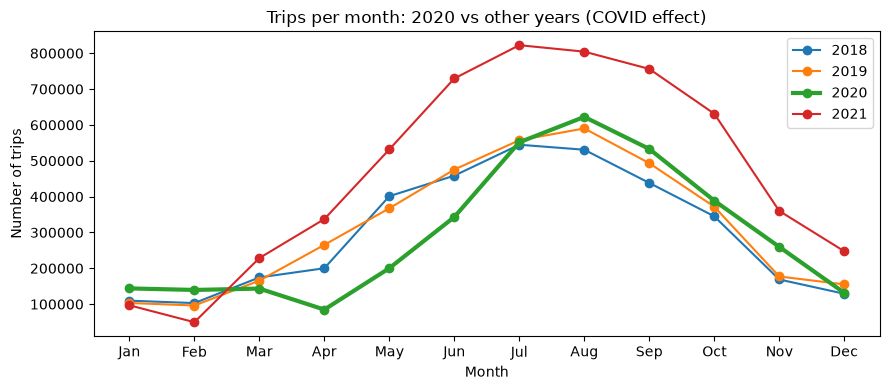

In [11]:
df = monthly.groupby("month")["n_trips"].sum().reset_index()
df["year"] = df["month"].dt.year
df["month_num"] = df["month"].dt.month

fig, ax = plt.subplots(figsize=(9, 4))
for year in [2018, 2019, 2020, 2021]:
    d = df[df["year"] == year]
    ax.plot(d["month_num"], d["n_trips"], marker="o", label=str(year),
            linewidth=3 if year == 2020 else 1.5)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("Trips per month: 2020 vs other years (COVID effect)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of trips")
ax.legend()
plt.tight_layout()
plt.show()